# Valutazione sperimentale della cartella clinica passwordless

Questo notebook analizza le misure raccolte sul **codice reale** del progetto: costi dei contratti, prestazioni della crittografia, robustezza della custodia delle chiavi e campagne d'attacco ripetute contro il backend. Le figure prodotte sono salvate in `figure/` e usate nella relazione.

**Da dove vengono i dati.** I file CSV in `dati/` sono prodotti dagli script di misura del repository:

| File | Script | Comando |
|---|---|---|
| `gas.csv` | `blockchain/scripts/gas.ts` | `npx hardhat run scripts/gas.ts` (cartella `blockchain`) |
| `firme.csv`, `cifratura.csv`, `componenti.csv`, `argon2.csv`, `ambiente.json` | `backend/bench/crypto.ts` | `npm run bench:crypto` (cartella `backend`) |
| `attacchi.csv`, `login_dos.csv` | `backend/bench/attacks.ts` | `npm run bench:attacchi` |
| `attacchi-prima-della-revisione.csv`, `login_dos-prima-della-revisione.csv` | stesso script, sul backend del commit precedente alla revisione di sicurezza | vedi sezione 8 |

I tempi dipendono dalla macchina: rigenerando i dati su un altro computer cambiano i valori assoluti, non le conclusioni. L'analisi di Shamir (sezione 7) è invece interamente calcolata qui.

## 1. Configurazione

In [1]:
import json
from math import comb, log2
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATI = Path("dati")
FIGURE = Path("figure")
FIGURE.mkdir(exist_ok=True)
SEED = 20261113                      # seed fisso: le parti casuali sono ripetibili
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
VERDE, ARANCIO, GRIGIO, ROSSO = "#17695D", "#D9822B", "#7A8B8F", "#B42318"

def salva(fig, nome):
    # PDF vettoriale per la relazione, PNG per una consultazione rapida.
    fig.savefig(FIGURE / f"{nome}.pdf", bbox_inches="tight")
    fig.savefig(FIGURE / f"{nome}.png", dpi=160, bbox_inches="tight")

ambiente = json.loads((DATI / "ambiente.json").read_text())
pd.Series(ambiente, name="macchina delle misure").to_frame()

,macchina delle misure
data,2026-11-13T14:03:22.691Z
node,v24.22.2
openssl,3.5.9
sistema,linux 6.18.44-fc-v445
cpu,Intel(R) Xeon(R) Processor @ 2.10GHz
core,2
memoria_gib,8


## 2. Controlli preliminari sui dati
Prima di analizzare: i file ci sono, hanno il numero di righe atteso e non contengono valori mancanti o impossibili.

In [2]:
gas = pd.read_csv(DATI / "gas.csv")
firme = pd.read_csv(DATI / "firme.csv")
cifratura = pd.read_csv(DATI / "cifratura.csv")
componenti = pd.read_csv(DATI / "componenti.csv")
argon = pd.read_csv(DATI / "argon2.csv")
attacchi = pd.concat([pd.read_csv(DATI / "attacchi.csv"),
                      pd.read_csv(DATI / "attacchi-prima-della-revisione.csv")], ignore_index=True)
login_dos = pd.concat([pd.read_csv(DATI / "login_dos.csv"),
                       pd.read_csv(DATI / "login_dos-prima-della-revisione.csv")], ignore_index=True)

tabelle = {"gas": gas, "firme": firme, "cifratura": cifratura, "componenti": componenti,
           "argon2": argon, "attacchi": attacchi, "login_dos": login_dos}
controlli = pd.DataFrame({
    "righe": {k: len(v) for k, v in tabelle.items()},
    "valori mancanti": {k: int(v.isna().sum().sum()) for k, v in tabelle.items()},
})
assert controlli["valori mancanti"].sum() == 0
assert (gas.gas > 21000).all(), "ogni transazione costa almeno il gas di base (21000)"
assert set(attacchi[["attacco_riuscito", "legittimo_riuscito"]].stack().unique()) <= {0, 1}
controlli

,righe,valori mancanti
gas,1055,0
firme,600,0
cifratura,560,0
componenti,3000,0
argon2,140,0
attacchi,570,0
login_dos,360,0


## 3. Costi on-chain (gas)

Ogni scrittura sulla blockchain costa gas. Le operazioni frequenti sono la registrazione di un accesso (a ogni apertura di cartella e a ogni referto firmato) e, più raramente, la concessione o la revoca di un consenso. Le misure sono state ripetute su 150 pazienti diversi.

In [3]:
operazioni = gas[gas.operazione.isin(["grantConsent", "revokeConsent", "recordAccess", "recordEmergencyAccess"])]
riepilogo_gas = (operazioni.groupby(["operazione", "variante"]).gas
                 .agg(minimo="min", mediana="median", massimo="max", misure="count").astype(int))
riepilogo_gas

minimo  mediana  massimo  \
operazione            variante                                              
grantConsent          prima concessione           49967    49967    49967   
                      rinnovo (stessa finalità)   32867    32867    32867   
                      seconda finalità            49967    49979    49979   
recordAccess          concesso                    41896    41908    59008   
                      negato                      34827    34839    34839   
recordEmergencyAccess d'emergenza                 36769    36781    36781   
revokeConsent         revoca                      24718    24718    24718   

                                                 misure  
operazione            variante                           
grantConsent          prima concessione             150  
                      rinnovo (stessa finalità)     150  
                      seconda finalità              150  
recordAccess          concesso                      150  
                      negato                        150  
recordEmergencyAccess d'emergenza                   150  
revokeConsent         revoca                        150

La prima voce del registro di audit costa di più delle successive: il contatore `totalEntries` passa da zero a un valore non nullo, e scrivere uno slot di memoria vuoto costa più che aggiornarne uno già usato. Lo stesso vale per la prima concessione di un consenso rispetto al rinnovo. Per il resto il costo non dipende da quanti pazienti o voci esistono già, come mostra il grafico: nessuna operazione contiene cicli su dati che crescono (assenza di DoS per consumo di gas).

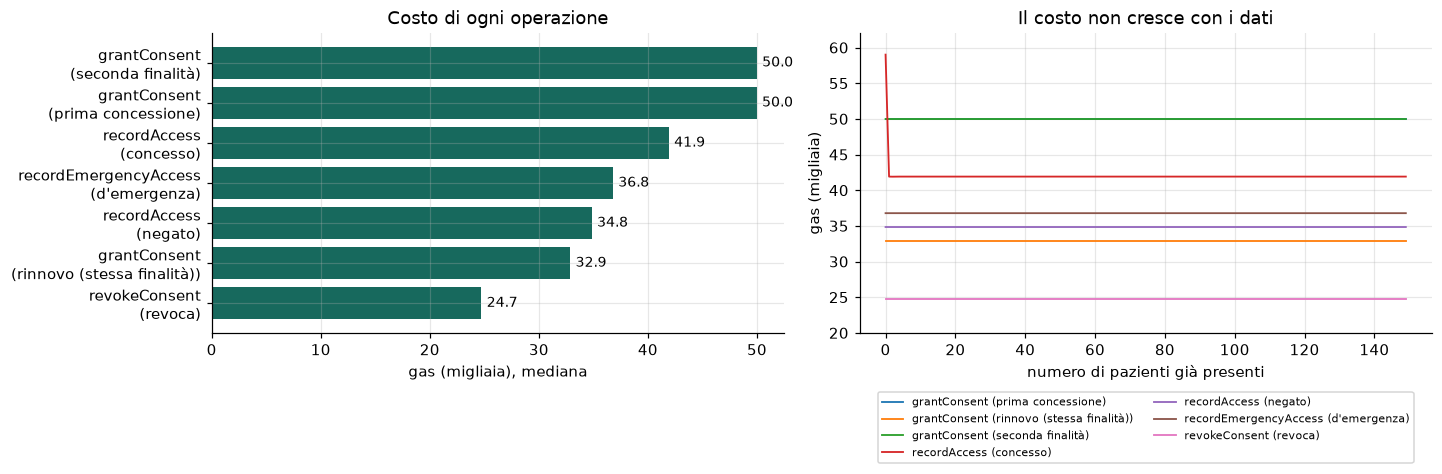

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
mediane = operazioni.groupby(["operazione", "variante"]).gas.median().sort_values()
etichette = [f"{o}\n({v})" for o, v in mediane.index]
a1.barh(etichette, mediane.values / 1000, color=VERDE)
for y, val in enumerate(mediane.values):
    a1.text(val / 1000 + 0.5, y, f"{val / 1000:.1f}", va="center", fontsize=9)
a1.set_xlabel("gas (migliaia), mediana"); a1.set_title("Costo di ogni operazione")

for (op, var), g in operazioni.groupby(["operazione", "variante"]):
    a2.plot(g.indice, g.gas / 1000, lw=1.2, label=f"{op} ({var})")
a2.set_xlabel("numero di pazienti già presenti"); a2.set_ylabel("gas (migliaia)")
a2.set_title("Il costo non cresce con i dati"); a2.set_ylim(20, 62)
a2.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
salva(fig, "gas_operazioni")
plt.show()

### Costo annuo stimato
Il costo in euro dipende da due grandezze che cambiano di continuo, il prezzo del gas e il prezzo dell'ether, e da quanto il sistema viene usato. Per questo il calcolo è parametrico: i valori sotto sono **ipotesi** da modificare, non dati misurati.

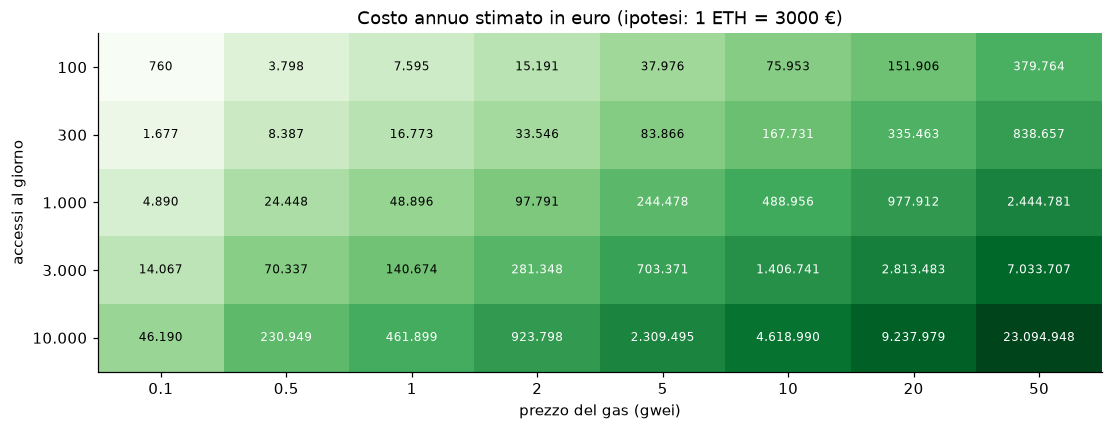

In [5]:
ETH_EUR = 3000                     # ipotesi sul prezzo dell'ether in euro
CONSENSI_AL_GIORNO = 50            # nuove concessioni o rinnovi
REVOCHE_AL_GIORNO = 10
g = operazioni.groupby(["operazione", "variante"]).gas.median()
gas_accesso = g[("recordAccess", "concesso")]
gas_consenso = g[("grantConsent", "prima concessione")]
gas_revoca = g[("revokeConsent", "revoca")]

prezzi_gwei = np.array([0.1, 0.5, 1, 2, 5, 10, 20, 50])
accessi_giorno = np.array([100, 300, 1000, 3000, 10000])
def euro_anno(accessi, gwei):
    gas_giorno = accessi * gas_accesso + CONSENSI_AL_GIORNO * gas_consenso + REVOCHE_AL_GIORNO * gas_revoca
    return gas_giorno * 365 * gwei * 1e-9 * ETH_EUR

griglia = np.array([[euro_anno(a, p) for p in prezzi_gwei] for a in accessi_giorno])
fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
im = ax.imshow(np.log10(griglia), cmap="Greens", aspect="auto")
ax.set_xticks(range(len(prezzi_gwei)), [f"{p:g}" for p in prezzi_gwei])
ax.set_yticks(range(len(accessi_giorno)), [f"{a:,}".replace(",", ".") for a in accessi_giorno])
ax.set_xlabel("prezzo del gas (gwei)"); ax.set_ylabel("accessi al giorno")
ax.set_title(f"Costo annuo stimato in euro (ipotesi: 1 ETH = {ETH_EUR} €)")
for i in range(len(accessi_giorno)):
    for j in range(len(prezzi_gwei)):
        v = griglia[i, j]
        ax.text(j, i, f"{v:,.0f}".replace(",", "."), ha="center", va="center", fontsize=8,
                color="white" if np.log10(v) > np.log10(griglia).mean() else "black")
ax.grid(False)
salva(fig, "gas_costo_annuo")
plt.show()

Sulla rete principale di Ethereum, con molti accessi e un prezzo del gas alto, il costo diventa rilevante; con prezzi bassi resta contenuto. È un argomento in più, accanto alla riservatezza dei metadati, a favore di una rete *permissioned* o di una rete di secondo livello, dove il costo per transazione è molto più basso.

## 4. Firme: ES256 e ML-DSA-44

Il backend accetta passkey classiche (ES256) e post-quantistiche (ML-DSA-44, FIPS 204). Le misure usano l'autenticatore software del progetto e la stessa funzione di verifica del server: 300 firme per algoritmo, dopo 20 di riscaldamento.

In [6]:
riepilogo_firme = firme.groupby("algoritmo").agg(
    chiave_pubblica_byte=("byte_chiave_pubblica", "first"),
    firma_byte=("byte_firma", "first"),
    risposta_byte=("byte_risposta", "median"),
    firma_ms_mediana=("firma_ms", "median"),
    verifica_ms_mediana=("verifica_ms", "median"),
    verifica_ms_p95=("verifica_ms", lambda s: s.quantile(0.95)),
)
riepilogo_firme.round(3)

,chiave_pubblica_byte,firma_byte,risposta_byte,firma_ms_mediana,verifica_ms_mediana,verifica_ms_p95
algoritmo,,,,,,
ES256,77,71,507.0,0.096,0.536,1.163
ML-DSA-44,1322,2420,3639.0,0.607,0.508,1.172


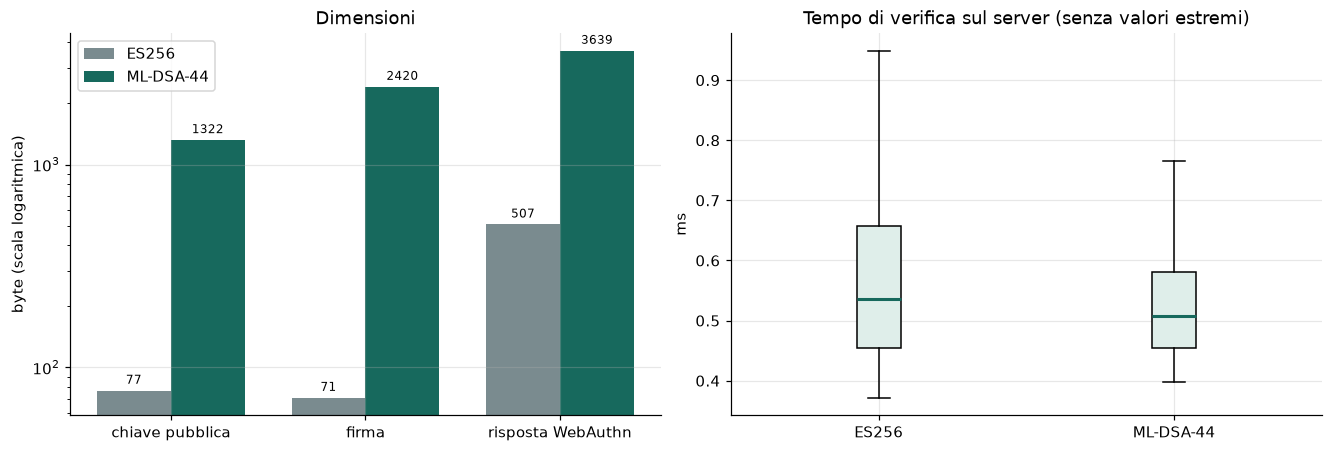

La firma ML-DSA-44 è 34 volte più grande, la chiave pubblica 17 volte; la verifica richiede 0.95 volte il tempo.


In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
voci = ["chiave_pubblica_byte", "firma_byte", "risposta_byte"]
nomi = ["chiave pubblica", "firma", "risposta WebAuthn"]
x = np.arange(len(voci)); w = 0.38
for k, (alg, col) in enumerate([("ES256", GRIGIO), ("ML-DSA-44", VERDE)]):
    vals = riepilogo_firme.loc[alg, voci].values.astype(float)
    a1.bar(x + (k - 0.5) * w, vals, w, label=alg, color=col)
    for xi, v in zip(x, vals):
        a1.text(xi + (k - 0.5) * w, v * 1.08, f"{v:.0f}", ha="center", fontsize=8)
a1.set_yscale("log"); a1.set_xticks(x, nomi); a1.set_ylabel("byte (scala logaritmica)")
a1.set_title("Dimensioni"); a1.legend()

dati = [firme[firme.algoritmo == a].verifica_ms for a in ["ES256", "ML-DSA-44"]]
a2.boxplot(dati, tick_labels=["ES256", "ML-DSA-44"], showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#dfeeea"), medianprops=dict(color=VERDE, lw=2))
a2.set_ylabel("ms"); a2.set_title("Tempo di verifica sul server (senza valori estremi)")
salva(fig, "firme_confronto")
plt.show()

r = riepilogo_firme
print(f"La firma ML-DSA-44 è {r.loc['ML-DSA-44','firma_byte'] / r.loc['ES256','firma_byte']:.0f} volte più grande, "
      f"la chiave pubblica {r.loc['ML-DSA-44','chiave_pubblica_byte'] / r.loc['ES256','chiave_pubblica_byte']:.0f} volte; "
      f"la verifica richiede {r.loc['ML-DSA-44','verifica_ms_mediana'] / r.loc['ES256','verifica_ms_mediana']:.2f} volte il tempo.")

Il prezzo della sicurezza post-quantistica è soprattutto nelle **dimensioni**: firme e chiavi decine di volte più grandi. Il tempo di verifica resta dello stesso ordine e, in assoluto, inferiore al millisecondo: per un login o una firma di referto non è un collo di bottiglia. Le dimensioni contano di più per i dispositivi e per i protocolli con limiti sui messaggi.

## 5. Cifratura ibrida dei referti

Ogni referto è cifrato con AES-256-GCM e la sua chiave è protetta da ML-KEM-768 e X25519 insieme. Misuriamo cifratura e decifratura al variare della dimensione del referto, il peso di ogni componente e quanti byte aggiunge lo schema.

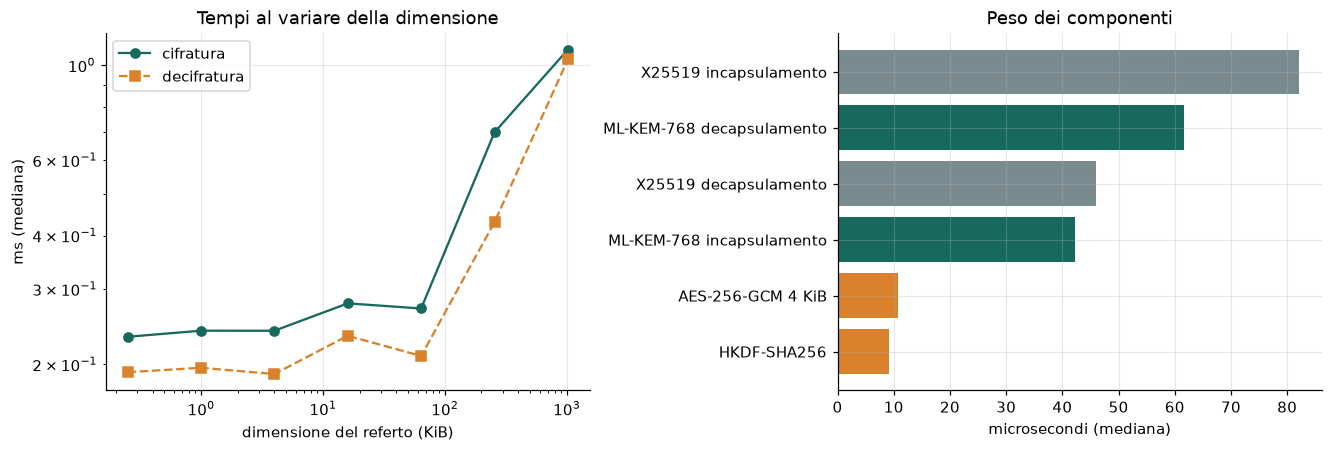

,cifra,decifra,cifrati,aggiunta_byte,aggiunta_%
byte_documento,,,,,
256,0.232,0.192,2053.0,1797.0,701.953
1024,0.240,0.196,3077.0,2053.0,200.488
4096,0.240,0.190,7173.0,3077.0,75.122
16384,0.278,0.233,23557.0,7173.0,43.781
65536,0.270,0.209,89093.0,23557.0,35.945
262144,0.697,0.430,351237.0,89093.0,33.986
1048576,1.088,1.032,1399813.0,351237.0,33.497


In [8]:
t = cifratura.groupby("byte_documento").agg(cifra=("cifra_ms", "median"), decifra=("decifra_ms", "median"),
                                             cifrati=("byte_cifrati_json", "median"))
t["aggiunta_byte"] = t.cifrati - t.index
t["aggiunta_%"] = 100 * t.aggiunta_byte / t.index
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
a1.loglog(t.index / 1024, t.cifra, "o-", color=VERDE, label="cifratura")
a1.loglog(t.index / 1024, t.decifra, "s--", color=ARANCIO, label="decifratura")
a1.set_xlabel("dimensione del referto (KiB)"); a1.set_ylabel("ms (mediana)")
a1.set_title("Tempi al variare della dimensione"); a1.legend()

comp = componenti.groupby("componente").microsecondi.median().sort_values()
colori = [VERDE if "ML-KEM" in c else GRIGIO if "X25519" in c else ARANCIO for c in comp.index]
a2.barh(comp.index, comp.values, color=colori)
a2.set_xlabel("microsecondi (mediana)"); a2.set_title("Peso dei componenti")
salva(fig, "cifratura_tempi")
plt.show()
t.round(3)

Per referti piccoli il tempo è dominato dai due KEM e dalla derivazione della chiave, che hanno costo fisso; oltre qualche centinaio di KiB domina AES-GCM, che cresce con la dimensione. In ogni caso si resta intorno al millisecondo anche per un referto di 1 MiB. ML-KEM-768 e X25519 costano lo stesso ordine di grandezza, qualche decina di microsecondi per operazione (in alcune esecuzioni ML-KEM è più rapido nell'incapsulamento e più lento nella decapsulazione): la parte post-quantistica **non è un costo in tempo**.

Lo spazio aggiunto merita invece attenzione. Si compone di una parte fissa, poco meno di 2 KB, dovuta soprattutto al testo cifrato di ML-KEM (1088 byte) e alla chiave cifrata, e di una parte proporzionale: i campi binari sono salvati come testo base64 dentro il documento JSON, e il base64 aumenta ogni contenuto di un terzo. Il grafico sotto lo mostra. Salvando i campi come dati binari di MongoDB l'aggiunta proporzionale sparirebbe: è un'ottimizzazione facile, annotata tra i limiti.

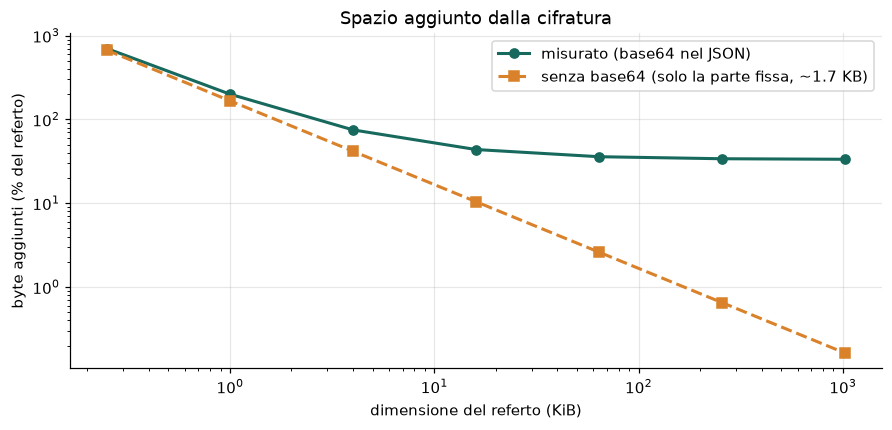

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
ax.semilogx(t.index / 1024, t["aggiunta_%"], "o-", color=VERDE, lw=2, label="misurato (base64 nel JSON)")
fisso = (t.aggiunta_byte - t.index / 3).median()
ax.semilogx(t.index / 1024, 100 * fisso / t.index, "s--", color=ARANCIO, lw=2, label=f"senza base64 (solo la parte fissa, ~{fisso / 1000:.1f} KB)")
ax.set_xlabel("dimensione del referto (KiB)"); ax.set_ylabel("byte aggiunti (% del referto)")
ax.set_yscale("log"); ax.set_title("Spazio aggiunto dalla cifratura"); ax.legend()
salva(fig, "cifratura_spazio")
plt.show()

## 6. Argon2id: quanto costa indovinare la passphrase

Le chiavi dell'archivio sono cifrate con una chiave derivata dalla passphrase tramite Argon2id. Il progetto usa la seconda configurazione raccomandata da RFC 9106 (64 MiB, 3 passate, parallelismo 4). Prima misuriamo il costo di un tentativo al variare dei parametri, poi stimiamo il tempo che servirebbe a un attaccante.

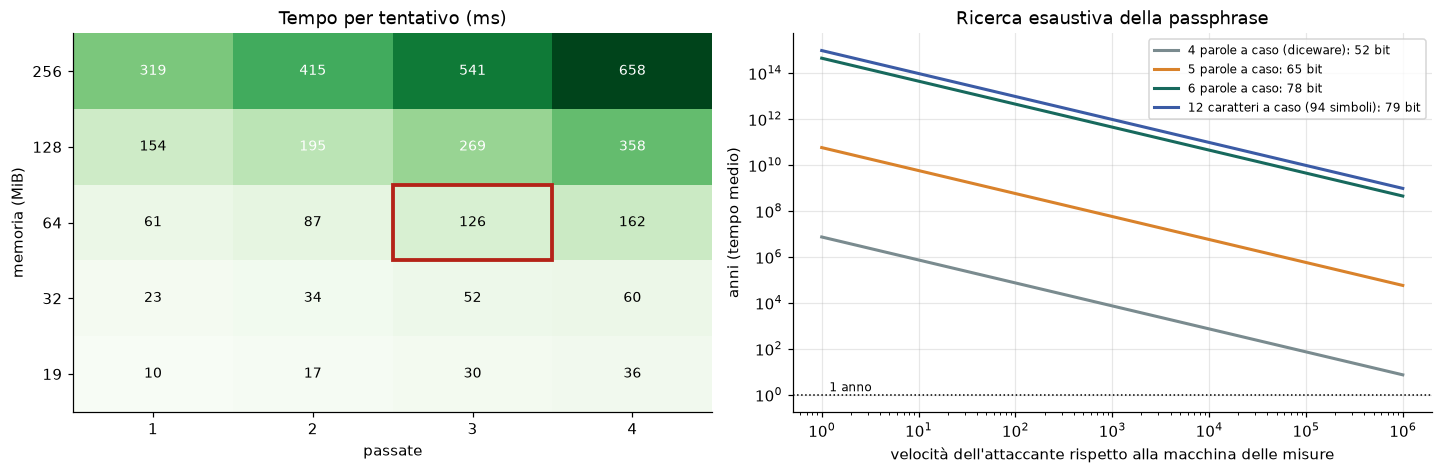

Un tentativo con i parametri del progetto costa 126 ms sulla macchina delle misure.


In [10]:
tabella = argon.groupby(["memoria_mib", "passate"]).ms.median().unstack()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
im = a1.imshow(tabella.values, cmap="Greens", aspect="auto", origin="lower")
a1.set_xticks(range(len(tabella.columns)), tabella.columns); a1.set_yticks(range(len(tabella.index)), tabella.index)
a1.set_xlabel("passate"); a1.set_ylabel("memoria (MiB)"); a1.set_title("Tempo per tentativo (ms)")
for i in range(tabella.shape[0]):
    for j in range(tabella.shape[1]):
        a1.text(j, i, f"{tabella.values[i, j]:.0f}", ha="center", va="center", fontsize=9,
                color="white" if tabella.values[i, j] > tabella.values.mean() else "black")
i, j = list(tabella.index).index(64), list(tabella.columns).index(3)
a1.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=ROSSO, lw=2.5)); a1.grid(False)

# Stima per l'attaccante: tempo medio per trovare la passphrase = metà dello spazio di ricerca
# per il costo di un tentativo, diviso per quanto l'attaccante è più veloce di noi.
t_tentativo = tabella.loc[64, 3] / 1000                      # secondi, configurazione del progetto
passphrase = {"4 parole a caso (diceware)": 4 * log2(7776), "5 parole a caso": 5 * log2(7776),
              "6 parole a caso": 6 * log2(7776), "12 caratteri a caso (94 simboli)": 12 * log2(94)}
accelerazioni = np.logspace(0, 6, 61)                         # da 1 a 1 milione di volte la nostra macchina
ANNO = 365.25 * 24 * 3600
for (nome, bit), col in zip(passphrase.items(), [GRIGIO, ARANCIO, VERDE, "#3B5BA5"]):
    anni = 2 ** (bit - 1) * t_tentativo / accelerazioni / ANNO
    a2.loglog(accelerazioni, anni, lw=2, color=col, label=f"{nome}: {bit:.0f} bit")
a2.axhline(1, color="k", ls=":", lw=1); a2.text(1.2, 1.4, "1 anno", fontsize=8)
a2.set_xlabel("velocità dell'attaccante rispetto alla macchina delle misure")
a2.set_ylabel("anni (tempo medio)"); a2.set_title("Ricerca esaustiva della passphrase"); a2.legend(fontsize=8)
salva(fig, "argon2_costo")
plt.show()
print(f"Un tentativo con i parametri del progetto costa {t_tentativo * 1000:.0f} ms sulla macchina delle misure.")

Il riquadro rosso indica la configurazione usata. La stima è volutamente semplice: assume una passphrase scelta **a caso** e un attaccante che conosce lo schema. La lunghezza minima di 12 caratteri imposta dal programma non garantisce da sola questa entropia: una frase nota o prevedibile ne ha molta meno. Argon2id rende ogni tentativo costoso anche su hardware specializzato, perché ogni tentativo richiede 64 MiB di memoria; il fattore di accelerazione sull'asse orizzontale rappresenta proprio i mezzi dell'attaccante.

## 7. Backup a soglia: quante quote e quante ne servono

Con lo schema di Shamir le chiavi si ricostruiscono con *k* quote su *n*. Due rischi si contrappongono: **perdere** le chiavi (meno di *k* custodi disponibili quando servono) e **rivelarle** (almeno *k* custodi compromessi). Assumiamo custodi indipendenti: ognuno non è disponibile con probabilità *p* ed è compromesso con probabilità *q*. Le probabilità si calcolano in forma chiusa con la distribuzione binomiale e si verificano con una simulazione Monte Carlo.

p=0.05: perdita esatta 0.00116, Monte Carlo 0.00112
p=0.2: perdita esatta 0.05792, Monte Carlo 0.05814


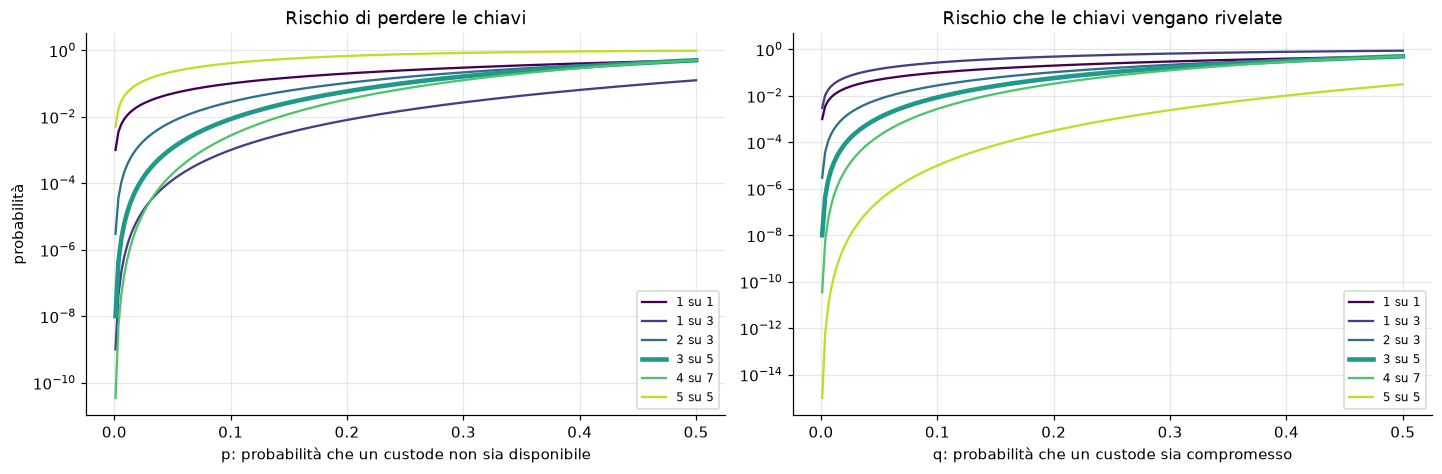

In [11]:
def binom_coda(n, k, x):
    # P(almeno k successi su n prove indipendenti con probabilità x)
    return sum(comb(n, i) * x**i * (1 - x)**(n - i) for i in range(k, n + 1))

def p_perdita(k, n, p):        # meno di k custodi disponibili
    return 1 - binom_coda(n, k, 1 - p)

def p_compromissione(k, n, q): # almeno k custodi compromessi
    return binom_coda(n, k, q)

# Verifica Monte Carlo della formula, per lo schema del progetto (3 su 5).
prove = 200_000
for p in [0.05, 0.2]:
    disponibili = (rng.random((prove, 5)) > p).sum(axis=1)
    print(f"p={p}: perdita esatta {p_perdita(3, 5, p):.5f}, Monte Carlo {np.mean(disponibili < 3):.5f}")

schemi = [(1, 1), (1, 3), (2, 3), (3, 5), (4, 7), (5, 5)]
xs = np.linspace(0.001, 0.5, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
for (k, n), col in zip(schemi, plt.cm.viridis(np.linspace(0, 0.9, len(schemi)))):
    lw = 3 if (k, n) == (3, 5) else 1.5
    a1.semilogy(xs, [p_perdita(k, n, x) for x in xs], color=col, lw=lw, label=f"{k} su {n}")
    a2.semilogy(xs, [p_compromissione(k, n, x) for x in xs], color=col, lw=lw, label=f"{k} su {n}")
a1.set_xlabel("p: probabilità che un custode non sia disponibile"); a1.set_ylabel("probabilità")
a1.set_title("Rischio di perdere le chiavi"); a1.legend(fontsize=8)
a2.set_xlabel("q: probabilità che un custode sia compromesso")
a2.set_title("Rischio che le chiavi vengano rivelate"); a2.legend(fontsize=8)
salva(fig, "shamir_rischi")
plt.show()

Una sola copia (1 su 1) è il caso peggiore su entrambi i fronti finché i custodi sono affidabili. Copie multiple senza soglia (1 su 3) quasi eliminano la perdita ma moltiplicano il rischio di furto; la soglia piena (5 su 5) fa il contrario. Gli schemi intermedi come 3 su 5 abbassano entrambi i rischi.

Per scegliere *k* e *n* conviene guardare il rischio **peggiore** dei due. La griglia lo calcola per tutti gli schemi fino a 7 custodi, con due ipotesi esplicite: ogni custode non è disponibile nel 10% dei casi e viene compromesso nel 5%.

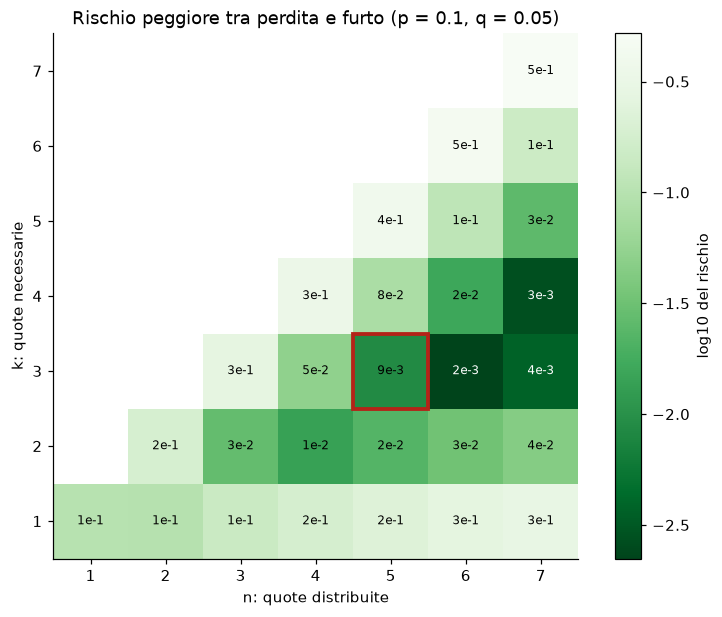

,rischio peggiore,k,n
0,0.002230,3,6
1,0.002728,4,7
2,0.003757,3,7
3,0.008560,3,5
4,0.014019,2,4


In [12]:
P_NON_DISPONIBILE, Q_COMPROMESSO = 0.10, 0.05      # ipotesi, da adattare all'organizzazione
N_MAX = 7
peggiore = np.full((N_MAX, N_MAX), np.nan)          # righe: k, colonne: n
for n in range(1, N_MAX + 1):
    for k in range(1, n + 1):
        peggiore[k - 1, n - 1] = max(p_perdita(k, n, P_NON_DISPONIBILE), p_compromissione(k, n, Q_COMPROMESSO))
fig, ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
im = ax.imshow(np.log10(peggiore), cmap="Greens_r", origin="lower")
for k in range(N_MAX):
    for n in range(N_MAX):
        if not np.isnan(peggiore[k, n]):
            ax.text(n, k, f"{peggiore[k, n]:.0e}".replace("e-0", "e-"), ha="center", va="center", fontsize=8,
                    color="white" if np.log10(peggiore[k, n]) < -2.2 else "black")
ax.add_patch(plt.Rectangle((5 - 1 - 0.5, 3 - 1 - 0.5), 1, 1, fill=False, ec=ROSSO, lw=2.5))
ax.set_xticks(range(N_MAX), range(1, N_MAX + 1)); ax.set_yticks(range(N_MAX), range(1, N_MAX + 1))
ax.set_xlabel("n: quote distribuite"); ax.set_ylabel("k: quote necessarie")
ax.set_title(f"Rischio peggiore tra perdita e furto (p = {P_NON_DISPONIBILE}, q = {Q_COMPROMESSO})")
fig.colorbar(im, ax=ax, label="log10 del rischio"); ax.grid(False)
salva(fig, "shamir_griglia")
plt.show()
migliori = sorted(((peggiore[k, n], k + 1, n + 1) for k in range(N_MAX) for n in range(N_MAX) if not np.isnan(peggiore[k, n])))[:5]
pd.DataFrame(migliori, columns=["rischio peggiore", "k", "n"])

Il riquadro rosso è lo schema del progetto (3 su 5). Con queste ipotesi i rischi più bassi si ottengono con soglie intorno alla metà del numero di custodi; aumentare *n* aiuta, ma ogni custode in più è una persona in più da coinvolgere. Con 5 custodi, 3 è la soglia che bilancia i due rischi.

## 8. Campagne d'attacco sul backend reale

Lo script `bench/attacks.ts` avvia il backend vero, con gli archivi in memoria, e ripete ogni attacco 30 volte con utenti nuovi. Per ogni prova registra due esiti: se l'attacco è riuscito e se l'**operazione legittima** corrispondente è ancora riuscita. Una difesa che bloccasse anche gli utenti onesti non sarebbe una buona difesa.

La colonna "prima della revisione" riguarda solo gli scenari di autenticazione, eseguiti anche sul backend del commit `1e078ed`, cioè com'era **prima della revisione di sicurezza** (sezione 7 della relazione). Per rigenerarli:

```
git worktree add ../prima-revisione 1e078ed
ln -s "$PWD/backend/node_modules" ../prima-revisione/backend/node_modules
cd backend && APP_DIR=../../prima-revisione/backend VERSIONE=prima-della-revisione npm run bench:attacchi
```

In [13]:
riepilogo = (attacchi.groupby(["scenario", "versione"])[["attacco_riuscito", "legittimo_riuscito"]]
             .mean().mul(100).round(0).unstack("versione"))
riepilogo

attacco_riuscito  \
versione                                                 attuale   
scenario                                                           
Accesso d'emergenza senza abilitazione                       0.0   
Blocco del login altrui (DoS)                                0.0   
Cartella aperta dopo la revoca del consenso                  0.0   
Cartella aperta per una finalità senza consenso              0.0   
Clone usato in parallelo all'originale                       0.0   
Enumerazione degli utenti                                    0.0   
Firma intercettata riusata da un collega                     0.0   
Passkey aggiunta all'account di un altro                     0.0   
Paziente che apre la cartella di un altro                    0.0   
Phishing: login da un sito clone                             0.0   
Referto firmato con la passkey di un altro                   0.0   
Referto scambiato nel database                               0.0   
Replay di una risposta di login                              0.0   

                                                                       \
versione                                        prima-della-revisione   
scenario                                                                
Accesso d'emergenza senza abilitazione                            NaN   
Blocco del login altrui (DoS)                                   100.0   
Cartella aperta dopo la revoca del consenso                       NaN   
Cartella aperta per una finalità senza consenso                   NaN   
Clone usato in parallelo all'originale                            0.0   
Enumerazione degli utenti                                       100.0   
Firma intercettata riusata da un collega                          NaN   
Passkey aggiunta all'account di un altro                          0.0   
Paziente che apre la cartella di un altro                         NaN   
Phishing: login da un sito clone                                  0.0   
Referto firmato con la passkey di un altro                        NaN   
Referto scambiato nel database                                    NaN   
Replay di una risposta di login                                   0.0   

                                                legittimo_riuscito  \
versione                                                   attuale   
scenario                                                             
Accesso d'emergenza senza abilitazione                       100.0   
Blocco del login altrui (DoS)                                100.0   
Cartella aperta dopo la revoca del consenso                  100.0   
Cartella aperta per una finalità senza consenso              100.0   
Clone usato in parallelo all'originale                       100.0   
Enumerazione degli utenti                                    100.0   
Firma intercettata riusata da un collega                     100.0   
Passkey aggiunta all'account di un altro                     100.0   
Paziente che apre la cartella di un altro                    100.0   
Phishing: login da un sito clone                             100.0   
Referto firmato con la passkey di un altro                   100.0   
Referto scambiato nel database                               100.0   
Replay di una risposta di login                              100.0   

                                                                       
versione                                        prima-della-revisione  
scenario                                                               
Accesso d'emergenza senza abilitazione                            NaN  
Blocco del login altrui (DoS)                                   100.0  
Cartella aperta dopo la revoca del consenso                       NaN  
Cartella aperta per una finalità senza consenso                   NaN  
Clone usato in parallelo all'originale                          100.0  
Enumerazione degli utenti                                       100.0  
Firma intercettata ri

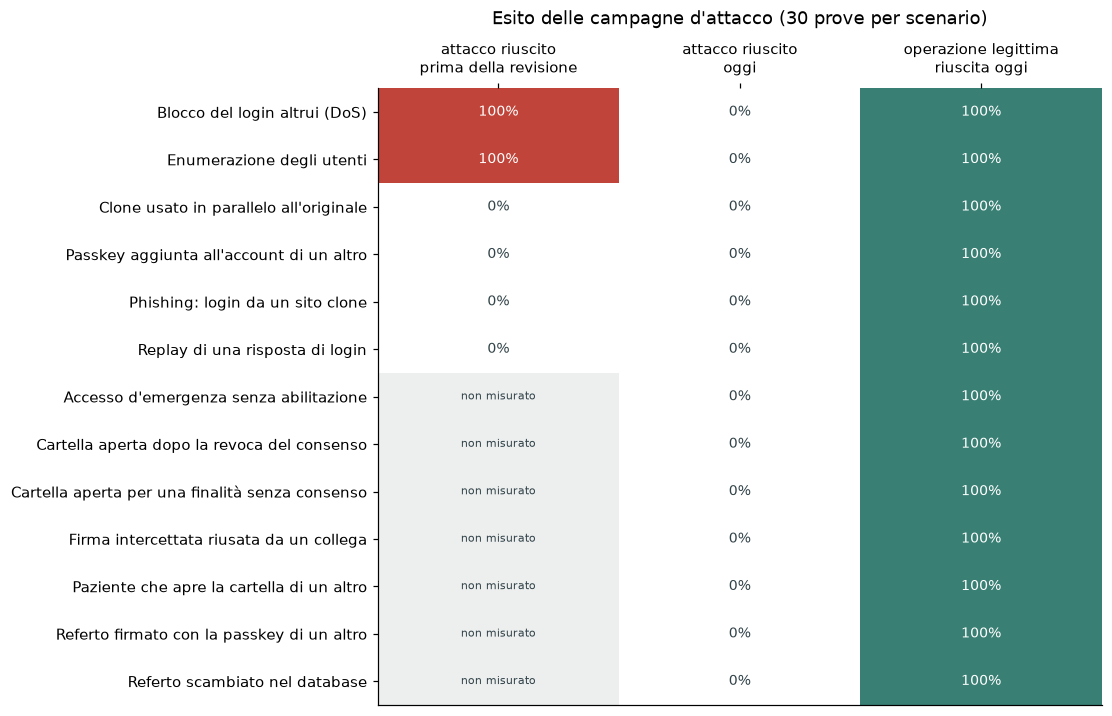

In [14]:
attuale = attacchi[attacchi.versione == "attuale"].groupby("scenario")[["attacco_riuscito", "legittimo_riuscito"]].mean() * 100
prima = attacchi[attacchi.versione != "attuale"].groupby("scenario").attacco_riuscito.mean() * 100
tab = pd.DataFrame({"attacco riuscito\nprima della revisione": prima.reindex(attuale.index),
                    "attacco riuscito\noggi": attuale.attacco_riuscito,
                    "operazione legittima\nriuscita oggi": attuale.legittimo_riuscito})
tab = tab.sort_values(["attacco riuscito\nprima della revisione", "attacco riuscito\noggi"], ascending=False)
# Colore: rosso dove riesce un attacco, verde dove riesce l'operazione legittima.
colori = np.zeros(tab.shape + (3,))
for j, col in enumerate(tab.columns):
    for i, v in enumerate(tab[col]):
        base = np.array([0.09, 0.41, 0.36]) if j == 2 else np.array([0.71, 0.14, 0.09])
        colori[i, j] = (0.93, 0.94, 0.94) if np.isnan(v) else 1 - (1 - base) * (v / 100) * 0.85 - 0.0
fig, ax = plt.subplots(figsize=(10, 6.4), layout="constrained")
ax.imshow(colori, aspect="auto")
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.iat[i, j]
        ax.text(j, i, "non misurato" if np.isnan(v) else f"{v:.0f}%", ha="center", va="center",
                fontsize=9 if not np.isnan(v) else 7, color="white" if (not np.isnan(v) and v > 60) else "#33444a")
ax.set_xticks(range(tab.shape[1]), tab.columns); ax.xaxis.tick_top()
ax.set_yticks(range(tab.shape[0]), tab.index); ax.grid(False)
ax.set_title("Esito delle campagne d'attacco (30 prove per scenario)", pad=42)
salva(fig, "attacchi_matrice")
plt.show()

Nella versione attuale nessun attacco riesce in nessuna prova, e tutte le operazioni legittime riescono. Il confronto con la versione precedente mostra i due problemi corretti dalla revisione: il **blocco del login altrui** e l'**enumerazione degli utenti** riuscivano nel 100% delle prove. Il clone usato in parallelo falliva anche prima, ma per una ragione accidentale (la challenge legata allo username impediva due login contemporanei): è la conferma sperimentale dei due problemi che si nascondevano a vicenda.

Attenzione all'interpretazione: zero successi su 30 prove non dimostra che un attacco sia impossibile. Dice che il controllo che lo blocca è sempre attivo, il che qui è atteso perché ogni controllo è deterministico.

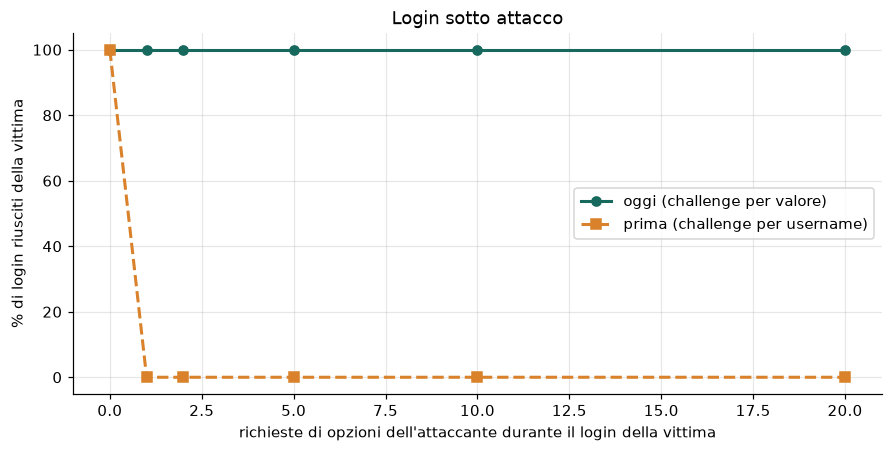

versione,attuale,prima-della-revisione
richieste_attaccante,,
0,100.0,100.0
1,100.0,0.0
2,100.0,0.0
5,100.0,0.0
10,100.0,0.0
20,100.0,0.0


In [15]:
curve = login_dos.groupby(["versione", "richieste_attaccante"]).vittima_entra.mean().mul(100).unstack("versione")
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(curve.index, curve["attuale"], "o-", color=VERDE, lw=2, label="oggi (challenge per valore)")
ax.plot(curve.index, curve["prima-della-revisione"], "s--", color=ARANCIO, lw=2, label="prima (challenge per username)")
ax.set_xlabel("richieste di opzioni dell'attaccante durante il login della vittima")
ax.set_ylabel("% di login riusciti della vittima"); ax.set_ylim(-5, 105)
ax.set_title("Login sotto attacco"); ax.legend()
salva(fig, "login_dos")
plt.show()
curve

Con il vecchio progetto basta **una sola** richiesta dell'attaccante nel momento giusto per far fallire il login della vittima; con quello attuale la vittima entra sempre, qualunque sia il numero di richieste. Il limite di frequenza (60 richieste al minuto per client) è stato alzato durante le misure per non confondere i due effetti.

## 9. Guida alla lettura e limiti

* **Che cosa si misura.** Il gas e gli esiti degli attacchi non dipendono dalla macchina; i tempi sì, e vanno letti come ordini di grandezza e come confronti relativi (ES256 contro ML-DSA, ML-KEM contro X25519).
* **Ipotesi dichiarate.** Il costo in euro (sezione 3) e la stima di forza bruta (sezione 6) dipendono da ipotesi esplicite nel codice: cambiandole cambiano i numeri, non il metodo.
* **Indipendenza dei custodi.** Il modello di Shamir assume custodi indipendenti; custodi che condividono un luogo o un sistema informatico hanno guasti correlati e il rischio reale è maggiore.
* **Campagne d'attacco.** Gli attacchi sono quelli del modello di minaccia, eseguiti contro il codice reale ma con archivi in memoria e una blockchain simulata. Non sostituiscono un penetration test, e zero successi su un numero finito di prove non è una dimostrazione.
* **Prestazioni.** I tempi della blockchain locale non rappresentano quelli di una rete reale, dove la conferma di un blocco richiede secondi; per questo non sono stati misurati.

## 10. Esportazione
I riepiloghi in forma tabellare vengono salvati accanto alle figure, per poterli citare nella relazione.

In [16]:
riepilogo_gas.to_csv(FIGURE / "riepilogo_gas.csv")
riepilogo_firme.round(4).to_csv(FIGURE / "riepilogo_firme.csv")
riepilogo.to_csv(FIGURE / "riepilogo_attacchi.csv")
sorted(p.name for p in FIGURE.iterdir())

['argon2_costo.pdf',
 'argon2_costo.png',
 'attacchi_matrice.pdf',
 'attacchi_matrice.png',
 'cifratura_spazio.pdf',
 'cifratura_spazio.png',
 'cifratura_tempi.pdf',
 'cifratura_tempi.png',
 'firme_confronto.pdf',
 'firme_confronto.png',
 'gas_costo_annuo.pdf',
 'gas_costo_annuo.png',
 'gas_operazioni.pdf',
 'gas_operazioni.png',
 'login_dos.pdf',
 'login_dos.png',
 'riepilogo_attacchi.csv',
 'riepilogo_firme.csv',
 'riepilogo_gas.csv',
 'shamir_griglia.pdf',
 'shamir_griglia.png',
 'shamir_rischi.pdf',
 'shamir_rischi.png']